# CardioIA — Ir Além 2: IA em séries temporais de batimentos

**Pergunta:** olhando só para a sequência de intervalos entre batimentos (intervalos RR), dá para detectar trechos com arritmia? E uma rede neuromórfica simples compete com um classificador tradicional?

**Por que intervalos RR:** é o mesmo sinal que o wearable da Fase 3 já produz (o tempo entre toques/batidas em `firmware/sketch/edge_logic.h`). Um modelo que funcione com RR poderia, em princípio, rodar no próprio dispositivo.

**Comparação:**

| Modelo | Entrada | O que é treinado |
|---|---|---|
| LR + atributos | 7 medidas clássicas de variabilidade | Pesos da regressão logística |
| LR + série bruta | 32 intervalos RR normalizados | Pesos da regressão logística |
| LIF (reservatório) | 32 intervalos RR como pulsos de corrente | Só a camada de saída; a rede de neurônios tem pesos aleatórios fixos |

**Aviso:** projeto acadêmico. Nada aqui serve para decisão clínica.

In [1]:
# No Google Colab, descomente a linha abaixo.
# %pip install -q wfdb scikit-learn

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEMENTE = 42
TAMANHO_JANELA = 32       # batimentos por janela: cerca de 25 s em ritmo normal
PASSO_JANELA = 16         # janelas com 50% de sobreposição
FRACAO_ECTOPICOS = 0.10   # janela é "anormal" com pelo menos 10% de batimentos ectópicos

# Salva figuras ao rodar pela raiz do repositório ou por notebooks/.
RAIZ = Path.cwd() if (Path.cwd() / 'assets').exists() else Path.cwd().parent
PASTA_FIGURAS = RAIZ / 'assets' / 'evidencias'
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Dados: MIT-BIH Arrhythmia Database

Dados reais, anonimizados e públicos: 48 registros de ECG de 47 pessoas, com cada batimento anotado por cardiologistas. Licença Open Data Commons Attribution v1.0. Só as anotações são baixadas (poucos kB por registro), o sinal de ECG não é necessário.

**Citações pedidas pela fonte:** Moody, G., & Mark, R. (2005). *MIT-BIH Arrhythmia Database* (v1.0.0). PhysioNet. https://doi.org/10.13026/C2F305 · Moody GB, Mark RG. *The impact of the MIT-BIH Arrhythmia Database.* IEEE Eng in Med and Biol 20(3):45-50 (2001).

**A divisão entre pacientes é a decisão mais importante deste notebook.** Sortear janelas ao acaso colocaria trechos da mesma pessoa no treino e no teste: o modelo reconheceria o paciente, e as métricas sairiam otimistas. Por isso partimos da divisão DS1/DS2 de De Chazal et al. (2004, *IEEE Trans. Biomed. Eng.* 51(7):1196-1206), que também exclui os quatro registros com marca-passo (102, 104, 107, 217).

**Um ajuste nosso:** a documentação do MIT-BIH informa que os registros 201 e 202 vêm da mesma pessoa, e a divisão original deixa um em cada lado. Retiramos o 202 do teste; assim nenhum paciente aparece nos dois conjuntos, e o teste fica com 21 registros.

In [2]:
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

# Agrupamento AAMI: N (e variantes de condução) é a classe normal; S, V e F são ectópicos.
# Q (desconhecido/marca-passo) é ignorado como rótulo, mas o batimento conta para o intervalo.
NORMAIS = set('NLRej')
ECTOPICOS = set('AaJSVEF')
BATIMENTOS = NORMAIS | ECTOPICOS | set('/fQ')


def carregar_registro(registro: int):
    ann = wfdb.rdann(str(registro), 'atr', pn_dir='mitdb')
    idx = [i for i, s in enumerate(ann.symbol) if s in BATIMENTOS]
    amostras = np.asarray(ann.sample)[idx]
    simbolos = np.asarray(ann.symbol)[idx]
    rr = np.diff(amostras) / ann.fs  # segundos
    ectopico = np.array([s in ECTOPICOS for s in simbolos[1:]])
    return rr, ectopico


def montar_janelas(registros):
    X, y, grupos = [], [], []
    for r in registros:
        rr, ect = carregar_registro(r)
        for i in range(0, len(rr) - TAMANHO_JANELA + 1, PASSO_JANELA):
            janela = rr[i:i + TAMANHO_JANELA]
            X.append(janela)
            y.append(ect[i:i + TAMANHO_JANELA].mean() >= FRACAO_ECTOPICOS)
            grupos.append(r)
    return np.array(X, dtype=np.float32), np.array(y, dtype=int), np.array(grupos)


inicio = time.time()
X_treino, y_treino, g_treino = montar_janelas(DS1)
X_teste, y_teste, g_teste = montar_janelas(DS2)
print(f'Download e janelas: {time.time() - inicio:.0f} s')

resumo = pd.DataFrame({
    'Pacientes (registros)': [len(set(g_treino)), len(set(g_teste))],
    'Janelas': [len(y_treino), len(y_teste)],
    'Janelas anormais': [int(y_treino.sum()), int(y_teste.sum())],
    '% anormais': [100 * y_treino.mean(), 100 * y_teste.mean()],
}, index=['Treino (DS1)', 'Teste (DS2)']).round(1)
assert not set(g_treino) & set(g_teste), 'Paciente nos dois conjuntos!'
resumo

Download e janelas: 59 s


,Pacientes (registros),Janelas,Janelas anormais,% anormais
Treino (DS1),22,3155,772,24.5
Teste (DS2),21,2943,944,32.1


### Como é o dado

Cada janela é normalizada pela própria mediana. Assim o modelo olha para a **irregularidade** do ritmo, e não para a frequência média de cada pessoa, o que também reduz o risco de ele decorar pacientes.

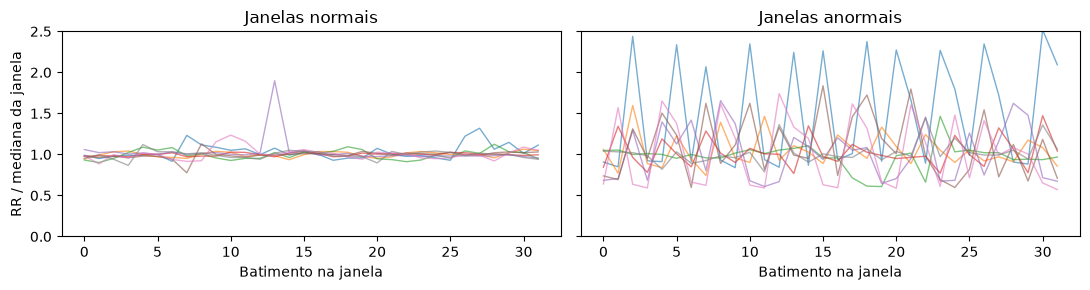

In [3]:
def normalizar(X):
    return X / np.median(X, axis=1, keepdims=True)


fig, eixos = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for eixo, classe, titulo in zip(eixos, [0, 1], ['Janelas normais', 'Janelas anormais']):
    rng_fig = np.random.default_rng(SEMENTE)
    escolhidas = rng_fig.choice(np.flatnonzero(y_treino == classe), 8, replace=False)
    eixo.plot(normalizar(X_treino[escolhidas]).T, alpha=.6, lw=1)
    eixo.set(title=titulo, xlabel='Batimento na janela', ylim=(0, 2.5))
eixos[0].set_ylabel('RR / mediana da janela')
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / 'ir_alem_2_series.png', dpi=130)
plt.show()

## 2. Modelos tradicionais

Os atributos são medidas clássicas de variabilidade da frequência cardíaca. `class_weight='balanced'` compensa o desbalanceamento entre classes.

In [4]:
def atributos(X):
    n = normalizar(X)
    dif = np.diff(n, axis=1)
    return np.column_stack([
        X.mean(axis=1),                                # RR médio absoluto (frequência)
        n.std(axis=1),                                 # SDNN relativo
        np.sqrt((dif ** 2).mean(axis=1)),              # RMSSD relativo
        (np.abs(dif) > 0.15).mean(axis=1),             # Fração de saltos > 15%
        n.min(axis=1),                                 # Batimento mais precoce
        n.max(axis=1),                                 # Maior pausa
        (np.abs(n - 1) > 0.15).mean(axis=1),           # Fração de batimentos fora do ritmo
    ])


def nova_lr(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight='balanced'))


def previsoes_fora_da_dobra(fabrica, F, y, grupos, n_dobras=5):
    """Previsões em pacientes fora do treino, usadas para escolher limiar e hiperparâmetros."""
    saida = np.zeros(len(y))
    for ind_tr, ind_va in GroupKFold(n_dobras).split(F, y, grupos):
        saida[ind_va] = fabrica().fit(F[ind_tr], y[ind_tr]).predict_proba(F[ind_va])[:, 1]
    return saida


F_attr_tr, F_attr_te = atributos(X_treino), atributos(X_teste)
F_raw_tr, F_raw_te = normalizar(X_treino), normalizar(X_teste)

print('AUC-PR em validação cruzada (DS1):')
print(f'  LR + atributos:   {average_precision_score(y_treino, previsoes_fora_da_dobra(nova_lr, F_attr_tr, y_treino, g_treino)):.3f}')
print(f'  LR + série bruta: {average_precision_score(y_treino, previsoes_fora_da_dobra(nova_lr, F_raw_tr, y_treino, g_treino)):.3f}')

AUC-PR em validação cruzada (DS1):
  LR + atributos:   0.801
  LR + série bruta: 0.463


## 3. Rede neuromórfica: reservatório de neurônios LIF

Um neurônio **LIF** (*Leaky Integrate-and-Fire*) acumula corrente em um potencial de membrana que vaza com o tempo. Ao cruzar o limiar, emite um pulso (*spike*) e reinicia:

$$v_{t+1} = v_t - \frac{v_t}{\tau} + I_t + \sum_j W_{ij}\, s_j(t), \qquad s_i(t)=1 \text{ se } v_i \ge 1$$

**Codificação:** cada batimento vira 10 passos de corrente, proporcional ao desvio do intervalo em relação à mediana. Adiantados e atrasados entram por dois canais separados.

**Treinamento:** usamos o desenho de reservatório (*Liquid State Machine*). Os pesos entre neurônios são aleatórios e fixos, e só uma regressão logística sobre as contagens de spikes é treinada. É o que há de mais simples em redes neuromórficas e dispensa *surrogate gradient*. **Consequência importante para ler os resultados:** este experimento avalia o reservatório, não o potencial máximo de redes de spikes treinadas de ponta a ponta.

In [5]:
PASSOS_POR_BATIMENTO = 10
TAU = 20.0
CORRENTE_BASE = 0.04      # Em repouso a membrana estabiliza em 0,8: abaixo do limiar, mas perto
REFRATARIO = 2


def criar_reservatorio(n, ganho_entrada, ganho_recorrente, semente, densidade=0.1, frac_inibitorios=0.2):
    rng = np.random.default_rng(semente)
    W_entrada = rng.uniform(0, ganho_entrada, (n, 2)) * (rng.random((n, 2)) < 0.3)
    W = rng.uniform(0, ganho_recorrente, (n, n)) * (rng.random((n, n)) < densidade)
    inibitorios = rng.random(n) < frac_inibitorios
    W[:, inibitorios] *= -4   # Inibição mais forte equilibra a rede
    np.fill_diagonal(W, 0)
    return W_entrada.astype(np.float32), W.astype(np.float32)


def simular_lif(X, W_entrada, W, tam_lote=1000):
    """Devolve as contagens de spikes por neurônio em cada janela (janelas x neurônios)."""
    n_neuronios = W.shape[0]
    n = normalizar(X)
    desvio = np.clip(n - 1, -1, 1)
    canais = np.stack([np.clip(desvio, 0, None), np.clip(-desvio, 0, None)], axis=2)  # janela, batida, canal

    contagens = np.zeros((len(X), n_neuronios), dtype=np.float32)
    for ini in range(0, len(X), tam_lote):
        lote = canais[ini:ini + tam_lote]
        corrente_batida = lote @ W_entrada.T      # janela, batida, neurônio
        v = np.zeros((len(lote), n_neuronios), dtype=np.float32)
        s = np.zeros_like(v)
        refr = np.zeros_like(v)
        for b in range(lote.shape[1]):
            for _ in range(PASSOS_POR_BATIMENTO):
                ativo = refr <= 0
                v = v - v / TAU + (CORRENTE_BASE + corrente_batida[:, b] + s @ W) * ativo
                s = (v >= 1).astype(np.float32)
                v = v * (1 - s)
                refr = np.where(s > 0, REFRATARIO, refr - 1)
                contagens[ini:ini + tam_lote] += s
    return contagens


# Sanidade do modelo: corrente base sozinha não dispara; pulso forte dispara.
_W_e, _W = np.ones((1, 2), dtype=np.float32), np.zeros((1, 1), dtype=np.float32)
assert simular_lif(np.ones((1, TAMANHO_JANELA), dtype=np.float32), _W_e * 0, _W)[0, 0] == 0
_x = np.ones((1, TAMANHO_JANELA), dtype=np.float32)
_x[0, ::2] = 1.5
assert simular_lif(_x, _W_e, _W)[0, 0] > 0

### Escolha de hiperparâmetros

Feita só em DS1, com validação cruzada por paciente. O conjunto de teste não participa.

In [6]:
N_NEURONIOS = 200
resultados = []
inicio = time.time()
for ganho_e in (0.05, 0.15, 0.5):
    for ganho_r in (0.0, 0.02, 0.05):
        W_e, W = criar_reservatorio(N_NEURONIOS, ganho_e, ganho_r, SEMENTE)
        S = simular_lif(X_treino, W_e, W)
        p = previsoes_fora_da_dobra(nova_lr, S, y_treino, g_treino)
        resultados.append({'ganho_entrada': ganho_e, 'ganho_recorrente': ganho_r,
                           'spikes_por_janela': S.sum(axis=1).mean(),
                           'AUC_PR_val': average_precision_score(y_treino, p)})
print(f'Busca: {time.time() - inicio:.0f} s')
tabela_busca = pd.DataFrame(resultados).sort_values('AUC_PR_val', ascending=False).round(3)
melhor = tabela_busca.iloc[0]
tabela_busca

Busca: 19 s


,ganho_entrada,ganho_recorrente,spikes_por_janela,AUC_PR_val
4,0.15,0.02,109.273003,0.771
7,0.50,0.02,373.050995,0.764
8,0.50,0.05,559.625977,0.762
6,0.50,0.00,364.709991,0.761
5,0.15,0.05,186.347000,0.754
3,0.15,0.00,106.675003,0.748
0,0.05,0.00,15.855000,0.718
2,0.05,0.05,23.160000,0.704
1,0.05,0.02,16.983000,0.697


## 4. Avaliação final no conjunto de teste

O **limiar de decisão** de cada modelo é fixado em DS1: o maior limiar que mantém sensibilidade ≥ 90%. Em triagem, um falso negativo é um paciente com arritmia que ninguém olha, então a sensibilidade vem primeiro. Só depois os modelos são aplicados a DS2, uma única vez.

Os **intervalos de confiança** reamostram pacientes, não janelas: janelas de um mesmo paciente não são independentes, e tratá-las como tal daria intervalos estreitos demais.

In [7]:
def limiar_para_sensibilidade(y, p, alvo=0.90):
    _, sens, limiares = precision_recall_curve(y, p)
    candidatos = limiares[sens[:-1] >= alvo]
    return candidatos.max()


def metricas(y, p, limiar):
    tn, fp, fn, tp = confusion_matrix(y, p >= limiar, labels=[0, 1]).ravel()
    return {
        'AUC-ROC': roc_auc_score(y, p), 'AUC-PR': average_precision_score(y, p),
        'Sensibilidade': tp / max(tp + fn, 1), 'Especificidade': tn / max(tn + fp, 1),
        'Precisão': tp / max(tp + fp, 1), 'F1': 2 * tp / max(2 * tp + fp + fn, 1),
    }


def ic_por_paciente(y, p, grupos, funcao, n=2000, semente=SEMENTE):
    rng = np.random.default_rng(semente)
    pacientes = np.unique(grupos)
    por_paciente = {g: np.flatnonzero(grupos == g) for g in pacientes}
    valores = []
    for _ in range(n):
        ind = np.concatenate([por_paciente[g] for g in rng.choice(pacientes, len(pacientes))])
        if y[ind].min() != y[ind].max():
            valores.append(funcao(y[ind], p[ind]))
    return np.percentile(valores, [2.5, 97.5])


def avaliar(fabrica, F_tr, F_te):
    p_val = previsoes_fora_da_dobra(fabrica, F_tr, y_treino, g_treino)
    limiar = limiar_para_sensibilidade(y_treino, p_val)
    p_te = fabrica().fit(F_tr, y_treino).predict_proba(F_te)[:, 1]
    m = metricas(y_teste, p_te, limiar)
    m['IC95 AUC-PR'] = ic_por_paciente(y_teste, p_te, g_teste, average_precision_score)
    return {'metricas': m, 'p': p_te, 'limiar': limiar}


saida = {}
for nome, F_tr, F_te in [('LR + atributos', F_attr_tr, F_attr_te), ('LR + série bruta', F_raw_tr, F_raw_te)]:
    saida[nome] = avaliar(nova_lr, F_tr, F_te)

# LIF: os pesos são sorteados; repetimos com 5 sementes para ver o quanto o resultado depende da sorte.
W_e, W = criar_reservatorio(N_NEURONIOS, melhor.ganho_entrada, melhor.ganho_recorrente, SEMENTE)
S_tr, S_te = simular_lif(X_treino, W_e, W), simular_lif(X_teste, W_e, W)
saida['LIF (reservatório)'] = avaliar(nova_lr, S_tr, S_te)

auc_sementes = []
for s in range(SEMENTE + 1, SEMENTE + 5):
    W_e_s, W_s = criar_reservatorio(N_NEURONIOS, melhor.ganho_entrada, melhor.ganho_recorrente, s)
    S_tr_s, S_te_s = simular_lif(X_treino, W_e_s, W_s), simular_lif(X_teste, W_e_s, W_s)
    auc_sementes.append(average_precision_score(y_teste, nova_lr().fit(S_tr_s, y_treino).predict_proba(S_te_s)[:, 1]))
auc_sementes.append(saida['LIF (reservatório)']['metricas']['AUC-PR'])
print(f'AUC-PR do LIF em 5 sementes: média {np.mean(auc_sementes):.3f}, desvio {np.std(auc_sementes):.3f}, faixa {min(auc_sementes):.3f}-{max(auc_sementes):.3f}')

linhas = []
for nome, r in saida.items():
    m = r['metricas']
    linhas.append({'Modelo': nome, **{k: round(v, 3) for k, v in m.items() if k != 'IC95 AUC-PR'},
                   'IC95 AUC-PR': f"{m['IC95 AUC-PR'][0]:.3f}-{m['IC95 AUC-PR'][1]:.3f}"})
tabela_final = pd.DataFrame(linhas).set_index('Modelo')
print(f'Referência de um modelo sem habilidade: AUC-PR = {y_teste.mean():.3f} (prevalência)')
tabela_final

AUC-PR do LIF em 5 sementes: média 0.724, desvio 0.013, faixa 0.711-0.747
Referência de um modelo sem habilidade: AUC-PR = 0.321 (prevalência)


,AUC-ROC,AUC-PR,Sensibilidade,Especificidade,Precisão,F1,IC95 AUC-PR
Modelo,,,,,,,
LR + atributos,0.923,0.849,0.868,0.781,0.652,0.744,0.628-0.964
LR + série bruta,0.599,0.547,0.992,0.008,0.321,0.485,0.290-0.743
LIF (reservatório),0.858,0.724,0.867,0.681,0.562,0.682,0.467-0.910


### A diferença entre os modelos é real?

Intervalos de confiança sobrepostos não respondem a essa pergunta: os dois modelos são avaliados nos mesmos pacientes, e um paciente difícil prejudica ambos. O certo é reamostrar pacientes e medir a **diferença** dentro de cada reamostragem.

In [8]:
def ic_diferenca(p_a, p_b, n=2000, semente=SEMENTE):
    rng = np.random.default_rng(semente)
    pacientes = np.unique(g_teste)
    por_paciente = {g: np.flatnonzero(g_teste == g) for g in pacientes}
    dif = []
    for _ in range(n):
        ind = np.concatenate([por_paciente[g] for g in rng.choice(pacientes, len(pacientes))])
        if y_teste[ind].min() != y_teste[ind].max():
            dif.append(average_precision_score(y_teste[ind], p_a[ind]) - average_precision_score(y_teste[ind], p_b[ind]))
    return np.mean(dif), *np.percentile(dif, [2.5, 97.5]), np.mean(np.array(dif) > 0)


media, baixo, alto, frac = ic_diferenca(saida['LR + atributos']['p'], saida['LIF (reservatório)']['p'])
print(f'AUC-PR (LR + atributos) - AUC-PR (LIF): {media:+.3f}, IC95 [{baixo:+.3f}, {alto:+.3f}]; LR melhor em {frac:.1%} das reamostragens')
media, baixo, alto, frac = ic_diferenca(saida['LIF (reservatório)']['p'], saida['LR + série bruta']['p'])
print(f'AUC-PR (LIF) - AUC-PR (LR + série bruta):   {media:+.3f}, IC95 [{baixo:+.3f}, {alto:+.3f}]; LIF melhor em {frac:.1%} das reamostragens')

AUC-PR (LR + atributos) - AUC-PR (LIF): +0.123, IC95 [+0.044, +0.222]; LR melhor em 100.0% das reamostragens


AUC-PR (LIF) - AUC-PR (LR + série bruta):   +0.186, IC95 [-0.049, +0.397]; LIF melhor em 94.5% das reamostragens


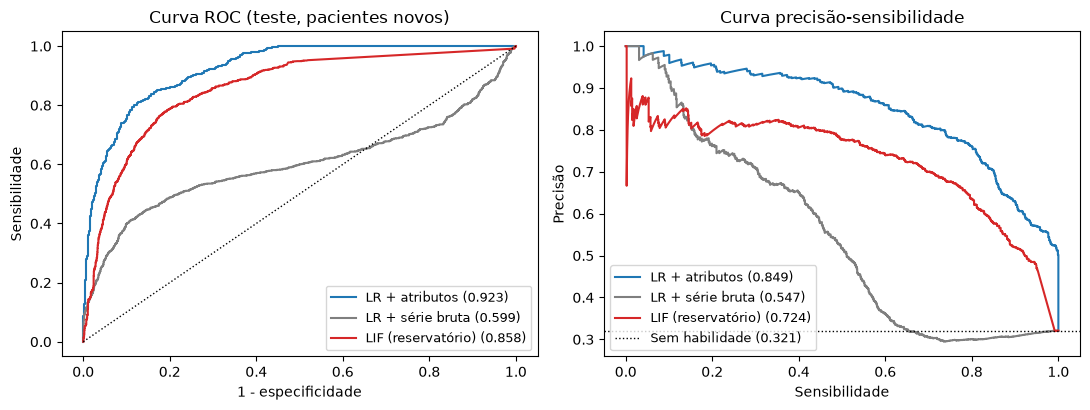

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
cores = {'LR + atributos': '#1f77b4', 'LR + série bruta': '#7f7f7f', 'LIF (reservatório)': '#d62728'}
for nome, r in saida.items():
    fpr, tpr, _ = roc_curve(y_teste, r['p'])
    pr, rc, _ = precision_recall_curve(y_teste, r['p'])
    eixos[0].plot(fpr, tpr, color=cores[nome], label=f"{nome} ({r['metricas']['AUC-ROC']:.3f})")
    eixos[1].plot(rc, pr, color=cores[nome], label=f"{nome} ({r['metricas']['AUC-PR']:.3f})")
eixos[0].plot([0, 1], [0, 1], 'k:', lw=1)
eixos[1].axhline(y_teste.mean(), color='k', ls=':', lw=1, label=f'Sem habilidade ({y_teste.mean():.3f})')
eixos[0].set(title='Curva ROC (teste, pacientes novos)', xlabel='1 - especificidade', ylabel='Sensibilidade')
eixos[1].set(title='Curva precisão-sensibilidade', xlabel='Sensibilidade', ylabel='Precisão')
for e in eixos:
    e.legend(fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / 'ir_alem_2_curvas.png', dpi=130)
plt.show()

### A média esconde pacientes?

Um bom número global pode conviver com pacientes em que o modelo falha por completo. Em saúde, isso importa tanto quanto a média.

Atenção ao ler a coluna da LR + série bruta: ela só atinge sensibilidade alta porque marca quase tudo como anormal (veja a especificidade na tabela anterior). Não é um bom resultado.

In [10]:
por_paciente = []
for g in np.unique(g_teste):
    ind = g_teste == g
    if y_teste[ind].sum() == 0:
        continue
    linha = {'Registro': g, 'Janelas': int(ind.sum()), 'Anormais': int(y_teste[ind].sum())}
    for nome, r in saida.items():
        linha[nome] = (r['p'][ind][y_teste[ind] == 1] >= r['limiar']).mean()
    por_paciente.append(linha)
tabela_paciente = pd.DataFrame(por_paciente).set_index('Registro').round(2)
print('Sensibilidade por paciente, só onde há janelas anormais:')
print(f"Pacientes com sensibilidade < 50%: " + ', '.join(f"{n}: {(tabela_paciente[n] < .5).sum()}" for n in saida))
tabela_paciente

Sensibilidade por paciente, só onde há janelas anormais:
Pacientes com sensibilidade < 50%: LR + atributos: 2, LR + série bruta: 0, LIF (reservatório): 1


,Janelas,Anormais,LR + atributos,LR + série bruta,LIF (reservatório)
Registro,,,,,
200,161,148,0.99,1.00,1.00
210,164,37,1.00,0.97,1.00
213,202,128,0.08,1.00,0.21
214,140,76,1.00,1.00,0.99
219,133,7,1.00,1.00,0.86
221,150,117,1.00,1.00,0.99
222,154,46,1.00,0.89,0.96
228,127,82,1.00,1.00,1.00
232,110,110,0.98,0.98,0.83


## 5. Custo computacional

A promessa do hardware neuromórfico é gastar energia só quando há spike. Como não temos esse hardware, contamos operações por janela. **É uma estimativa, não uma medição de energia.** Esta simulação atualiza toda membrana em todo passo; é a principal parcela da conta, e um chip orientado a eventos evitaria boa parte dela. O tempo de CPU também não representa um chip neuromórfico.

In [11]:
W_e, W = criar_reservatorio(N_NEURONIOS, melhor.ganho_entrada, melhor.ganho_recorrente, SEMENTE)
t0 = time.perf_counter(); S_todas = simular_lif(X_teste, W_e, W); t_lif = (time.perf_counter() - t0) / len(X_teste)
t0 = time.perf_counter(); atributos(X_teste); t_attr = (time.perf_counter() - t0) / len(X_teste)
t0 = time.perf_counter(); normalizar(X_teste); t_raw = (time.perf_counter() - t0) / len(X_teste)

spikes = S_todas.sum(axis=1).mean()
sinapses_por_neuron = (W != 0).sum() / N_NEURONIOS
passos = TAMANHO_JANELA * PASSOS_POR_BATIMENTO
custos = pd.DataFrame({
    'Parâmetros treinados': [7 + 1, TAMANHO_JANELA + 1, N_NEURONIOS + 1],
    'Parâmetros fixos': [0, 0, int((W != 0).sum() + (W_e != 0).sum())],
    'Operações por janela (aprox.)': [
        7 + 1 + 3 * TAMANHO_JANELA,          # Pesos + cálculo dos atributos
        TAMANHO_JANELA + 1,
        int(N_NEURONIOS * passos + spikes * sinapses_por_neuron + N_NEURONIOS + 1),  # Membranas + sinapses ativas + saída
    ],
    'Tempo de CPU por janela (ms)': [t_attr * 1e3, t_raw * 1e3, t_lif * 1e3],
}, index=['LR + atributos', 'LR + série bruta', 'LIF (reservatório)']).round(4)
print(f'Spikes por janela (todo o teste): média {spikes:.0f}, mediana {np.median(S_todas.sum(axis=1)):.0f}; '
      f'{spikes / (N_NEURONIOS * passos):.2%} dos pares neurônio-passo disparam')
print(f'Média de spikes: normais {S_todas[y_teste == 0].sum(axis=1).mean():.0f}, anormais {S_todas[y_teste == 1].sum(axis=1).mean():.0f}')
custos

Spikes por janela (todo o teste): média 131, mediana 56; 0.20% dos pares neurônio-passo disparam
Média de spikes: normais 64, anormais 273


,Parâmetros treinados,Parâmetros fixos,Operações por janela (aprox.),Tempo de CPU por janela (ms)
LR + atributos,8,0,104,0.0007
LR + série bruta,33,0,33,0.0003
LIF (reservatório),201,4076,66791,0.3483


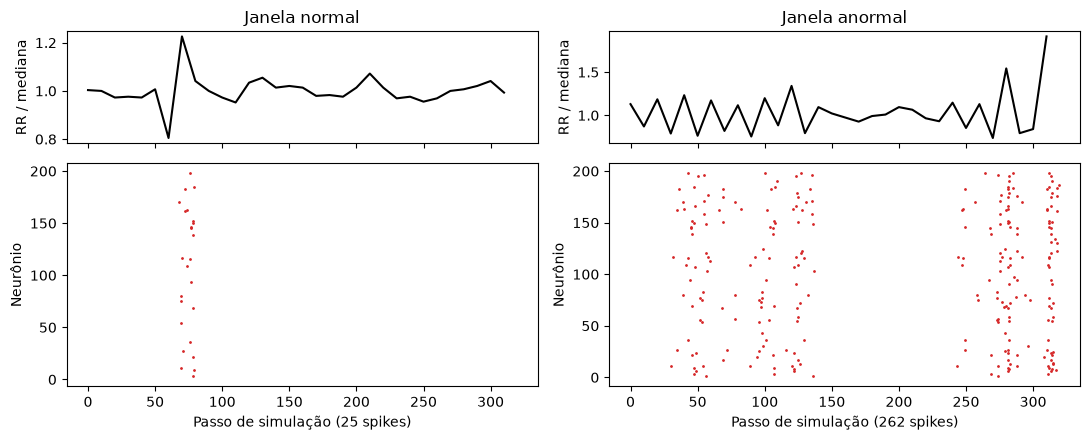

In [12]:
# Atividade da rede em uma janela normal e em uma anormal.
def raster(x):
    n_x = normalizar(x[None])
    d = np.clip(n_x - 1, -1, 1)
    canais = np.stack([np.clip(d, 0, None), np.clip(-d, 0, None)], axis=2)
    corrente = canais @ W_e.T
    v = np.zeros((1, N_NEURONIOS), dtype=np.float32); s = np.zeros_like(v); refr = np.zeros_like(v)
    pts = []
    t = 0
    for b in range(TAMANHO_JANELA):
        for _ in range(PASSOS_POR_BATIMENTO):
            ativo = refr <= 0
            v = v - v / TAU + (CORRENTE_BASE + corrente[:, b] + s @ W) * ativo
            s = (v >= 1).astype(np.float32); v = v * (1 - s)
            refr = np.where(s > 0, REFRATARIO, refr - 1)
            pts += [(t, i) for i in np.flatnonzero(s[0])]
            t += 1
    return np.array(pts).reshape(-1, 2)


fig, eixos = plt.subplots(2, 2, figsize=(11, 4.5), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
for c, (classe, titulo) in enumerate([(0, 'Janela normal'), (1, 'Janela anormal')]):
    i = np.flatnonzero(y_teste == classe)[0]
    eixos[0, c].plot(np.arange(TAMANHO_JANELA) * PASSOS_POR_BATIMENTO, normalizar(X_teste[i][None])[0], color='k')
    eixos[0, c].set(title=titulo, ylabel='RR / mediana')
    pts = raster(X_teste[i])
    eixos[1, c].scatter(pts[:, 0], pts[:, 1], s=1, color='#d62728')
    eixos[1, c].set(xlabel=f'Passo de simulação ({len(pts)} spikes)', ylabel='Neurônio')
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / 'ir_alem_2_raster.png', dpi=130)
plt.show()

## 6. Limitações

- **Intervalos RR vêm das anotações de especialistas**, ou seja, de batimentos perfeitamente detectados. Um wearable real erra batimentos, e o desempenho tende a cair.
- **Só o ritmo:** sem a forma do ECG, arritmias que mudam a morfologia sem alterar o tempo entre batidas ficam invisíveis.
- **Base antiga e pequena:** 43 registros de um único hospital, coletados de 1975 a 1979. Não representa a população brasileira atual.
- **O rótulo é uma definição nossa** (≥ 10% de batimentos ectópicos na janela), não um diagnóstico.
- **Reservatório sem treino interno:** os resultados não valem para redes de spikes treinadas com *surrogate gradient*, nem para outros modelos neuromórficos, como FHN.
- **Custo estimado:** contagem de operações, sem medição em hardware neuromórfico.